In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data=pd.read_csv('/Users/macbook/Desktop/cousera/DATA SCIENCE/NGO PROJECTS/UNICEF/adolescent girls.csv')

/var/folders/qj/qswms0r90q79_vs6_pmlnm340000gn/T/ipykernel_66006/4032544645.py:1: DtypeWarning: Columns (6,7,12,13,19,21) have mixed types. Specify dtype option on import or set low_memory=False.
  data=pd.read_csv('/Users/macbook/Desktop/cousera/DATA SCIENCE/NGO PROJECTS/UNICEF/adolescent girls.csv')


In [3]:
data.head(3)

,STRUCTURE,STRUCTURE_ID,ACTION,REF_AREA,INDICATOR,SEX,TIME_PERIOD,OBS_VALUE,UNIT_MULTIPLIER,UNIT_MEASURE,...,WGTD_SAMPL_SIZE,OBS_FOOTNOTE,SERIES_FOOTNOTE,DATA_SOURCE,SOURCE_LINK,CUSTODIAN,TIME_PERIOD_METHOD,REF_PERIOD,COVERAGE_TIME,AGE
0,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,FSM,CME_TMY15T24,M,1990,23.0,NaN,D,...,NaN,NaN,NaN,UN_IGME,NaN,NaN,NaN,NaN,NaN,_T
1,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,FSM,CME_TMY15T24,M,1991,23.0,NaN,D,...,NaN,NaN,NaN,UN_IGME,NaN,NaN,NaN,NaN,NaN,_T
2,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,FSM,CME_TMY15T24,M,1992,23.0,NaN,D,...,NaN,NaN,NaN,UN_IGME,NaN,NaN,NaN,NaN,NaN,_T


In [4]:
data.tail(3)

,STRUCTURE,STRUCTURE_ID,ACTION,REF_AREA,INDICATOR,SEX,TIME_PERIOD,OBS_VALUE,UNIT_MULTIPLIER,UNIT_MEASURE,...,WGTD_SAMPL_SIZE,OBS_FOOTNOTE,SERIES_FOOTNOTE,DATA_SOURCE,SOURCE_LINK,CUSTODIAN,TIME_PERIOD_METHOD,REF_PERIOD,COVERAGE_TIME,AGE
2747777,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_15TO24,F,2021,1286.779,3.0,PS,...,NaN,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,NaN,NaN,NaN,NaN,_T
2747778,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_15TO24,F,2022,1324.196,3.0,PS,...,NaN,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,NaN,NaN,NaN,NaN,_T
2747779,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_15TO24,F,2023,1361.927,3.0,PS,...,NaN,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,NaN,NaN,NaN,NaN,_T


In [5]:
data.isnull().sum()

STRUCTURE                   0
STRUCTURE_ID                0
ACTION                      0
REF_AREA                    0
INDICATOR                   0
SEX                         0
TIME_PERIOD                 0
OBS_VALUE                   0
UNIT_MULTIPLIER       1308785
UNIT_MEASURE                0
OBS_STATUS             618715
OBS_CONF              2365690
LOWER_BOUND           1792578
UPPER_BOUND           1792626
WGTD_SAMPL_SIZE       2717552
OBS_FOOTNOTE          2508561
SERIES_FOOTNOTE       2546565
DATA_SOURCE             91903
SOURCE_LINK           1402975
CUSTODIAN             2629975
TIME_PERIOD_METHOD    2507304
REF_PERIOD            2746934
COVERAGE_TIME         2539304
AGE                         0
dtype: int64

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2747780 entries, 0 to 2747779
Data columns (total 24 columns):
 #   Column              Dtype  
---  ------              -----  
 0   STRUCTURE           object 
 1   STRUCTURE_ID        object 
 2   ACTION              object 
 3   REF_AREA            object 
 4   INDICATOR           object 
 5   SEX                 object 
 6   TIME_PERIOD         object 
 7   OBS_VALUE           object 
 8   UNIT_MULTIPLIER     float64
 9   UNIT_MEASURE        object 
 10  OBS_STATUS          object 
 11  OBS_CONF            object 
 12  LOWER_BOUND         object 
 13  UPPER_BOUND         object 
 14  WGTD_SAMPL_SIZE     float64
 15  OBS_FOOTNOTE        object 
 16  SERIES_FOOTNOTE     object 
 17  DATA_SOURCE         object 
 18  SOURCE_LINK         object 
 19  CUSTODIAN           object 
 20  TIME_PERIOD_METHOD  object 
 21  REF_PERIOD          object 
 22  COVERAGE_TIME       object 
 23  AGE                 object 
dtypes: float64(2), object(22

In [7]:
#percentage of missing data
missing_percentage=(data.isnull().sum()/len(data))*100
print(missing_percentage[missing_percentage>50])

OBS_CONF              86.094593
LOWER_BOUND           65.237319
UPPER_BOUND           65.239066
WGTD_SAMPL_SIZE       98.899912
OBS_FOOTNOTE          91.294099
SERIES_FOOTNOTE       92.677179
SOURCE_LINK           51.058491
CUSTODIAN             95.712721
TIME_PERIOD_METHOD    91.248353
REF_PERIOD            99.969212
COVERAGE_TIME         92.412930
dtype: float64


In [8]:
# 2. Drop columns with more than 80% missing data, 
# BUT explicitly protect essential analytical columns if needed
threshold=80.0
col_to_drop=missing_percentage[missing_percentage>threshold].index
col_to_drop

Index(['OBS_CONF', 'WGTD_SAMPL_SIZE', 'OBS_FOOTNOTE', 'SERIES_FOOTNOTE',
       'CUSTODIAN', 'TIME_PERIOD_METHOD', 'REF_PERIOD', 'COVERAGE_TIME'],
      dtype='object')

In [9]:
data_clean=data.drop(columns=col_to_drop)
data_clean.head(5)


,STRUCTURE,STRUCTURE_ID,ACTION,REF_AREA,INDICATOR,SEX,TIME_PERIOD,OBS_VALUE,UNIT_MULTIPLIER,UNIT_MEASURE,OBS_STATUS,LOWER_BOUND,UPPER_BOUND,DATA_SOURCE,SOURCE_LINK,AGE
0,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,FSM,CME_TMY15T24,M,1990,23.0,NaN,D,A,18.0,30.0,UN_IGME,NaN,_T
1,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,FSM,CME_TMY15T24,M,1991,23.0,NaN,D,A,18.0,30.0,UN_IGME,NaN,_T
2,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,FSM,CME_TMY15T24,M,1992,23.0,NaN,D,A,18.0,30.0,UN_IGME,NaN,_T
3,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,FSM,CME_TMY15T24,M,1993,24.0,NaN,D,A,18.0,30.0,UN_IGME,NaN,_T
4,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,FSM,CME_TMY15T24,M,1994,23.0,NaN,D,A,18.0,30.0,UN_IGME,NaN,_T


In [10]:
print('default data_shape:',data.shape )
print('data_clean_shape:',data_clean.shape)

default data_shape: (2747780, 24)
data_clean_shape: (2747780, 16)


In [11]:
data_clean.tail(40)

,STRUCTURE,STRUCTURE_ID,ACTION,REF_AREA,INDICATOR,SEX,TIME_PERIOD,OBS_VALUE,UNIT_MULTIPLIER,UNIT_MEASURE,OBS_STATUS,LOWER_BOUND,UPPER_BOUND,DATA_SOURCE,SOURCE_LINK,AGE
2747740,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_15TO24,F,1984,419.36,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
2747741,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_15TO24,F,1985,433.169,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
2747742,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_15TO24,F,1986,447.009,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
2747743,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_15TO24,F,1987,460.923,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
2747744,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_15TO24,F,1988,475.095,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
2747745,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_15TO24,F,1989,489.652,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
2747746,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_15TO24,F,1990,504.717,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
2747747,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_15TO24,F,1991,520.326,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
2747748,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_15TO24,F,1992,536.588,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
2747749,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_15TO24,F,1993,565.664,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T


In [12]:
top_indicators=data_clean['INDICATOR'].value_counts().head(10)
print(top_indicators)

INDICATOR
DM_POP_TOT            94128
DM_POP_ADLCNT         94128
DM_POP_U5             94128
DM_POP_15TO24         94128
DM_POP_CHILD_PROP     93906
DM_POP_ADLCNT_PROP    93906
DM_POP_U18            86654
DM_LIFE_EXP           69486
DM_DPR_TOT            51948
DM_DPR_OLD            51948
Name: count, dtype: int64


In [13]:
demo_indicators=['DM_POP_TOT','DM_POP_ADLCNT','DM_POP_U5','DM_POP_15TO24','DM_POP_CHILD_PROP','DM_POP_ADLCNT_PROP','DM_POP_U18']

In [14]:
demo_data=data_clean[data_clean['INDICATOR'].isin(demo_indicators)]

In [15]:
print(demo_data.groupby(['INDICATOR','TIME_PERIOD'])['OBS_VALUE'].value_counts().head(10))

INDICATOR      TIME_PERIOD  OBS_VALUE
DM_POP_15TO24  1950         1387.08      3
                            2678.188     3
                            85884.107    3
                            10950.146    2
                            1291.107     2
                            1464.27      2
                            15962.781    2
                            16329.801    2
                            16367.662    2
                            16389.191    2
Name: count, dtype: int64


In [16]:
#define the demographic indicator we want to analyse

In [17]:
demo_indicators1=['DM_POP_TOT','DM_POP_ADLCNT','DM_POP_ADLCNT_PROP','DM_POP_15TO24']

In [18]:
#filter demo for these indicators
filtered_demo=data_clean[data_clean['INDICATOR'].isin(demo_indicators)].copy()

In [19]:
# 3. Quick check: view unique countries/areas (REF_AREA) available in this subset

In [20]:
print(f"\toltal rows for demographic indicators:{len(filtered_demo):,}")
print(f"Number of unique regions/countries (REF_AREA): {filtered_demo['REF_AREA'].nunique()}")

	oltal rows for demographic indicators:650,978
Number of unique regions/countries (REF_AREA): 424


In [21]:
filtered_demo['TIME_PERIOD']=pd.to_numeric(filtered_demo['TIME_PERIOD'], errors='coerce')

In [22]:
#find the latest years available for these indicators

In [23]:
latest_year=filtered_demo['TIME_PERIOD'].max()
print(f"\ latest years in dataset:{latest_year}")


\ latest years in dataset:2023


In [24]:
latest_adolescent_data=filtered_demo[
    (filtered_demo['TIME_PERIOD']==latest_year)&
    (filtered_demo['INDICATOR']=='DM_POP_ADLCNT')&
    (filtered_demo['SEX']=='F')
]

In [25]:
latest_adolescent_data.head(4)

,STRUCTURE,STRUCTURE_ID,ACTION,REF_AREA,INDICATOR,SEX,TIME_PERIOD,OBS_VALUE,UNIT_MULTIPLIER,UNIT_MEASURE,OBS_STATUS,LOWER_BOUND,UPPER_BOUND,DATA_SOURCE,SOURCE_LINK,AGE
203,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,BEN,DM_POP_ADLCNT,F,2023,1590.27,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
3430,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,MEX,DM_POP_ADLCNT,F,2023,11037.025,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
9473,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,FSM,DM_POP_ADLCNT,F,2023,11.754,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
16722,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,UNDEV_57,DM_POP_ADLCNT,F,2023,48.199,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T


In [26]:
# 1. Ensure OBS_VALUE is numeric (handles any text/mixed data types)
filtered_demo['OBS_VALUE'] = pd.to_numeric(filtered_demo['OBS_VALUE'], errors='coerce')

# 2. Filter for the latest year, female adolescent population
latest_adolescent_data = filtered_demo[
    (filtered_demo['TIME_PERIOD'] == latest_year) & 
    (filtered_demo['INDICATOR'] == 'DM_POP_ADLCNT') & 
    (filtered_demo['SEX'] == 'F')
].copy()

# 3. Sort by highest population values safely
top_adolescent_populations = latest_adolescent_data.sort_values(by='OBS_VALUE', ascending=False).head(10)

print(f"\nTop 10 Regions/Countries by Adolescent Girls Population ({latest_year}):")
print(top_adolescent_populations[['REF_AREA', 'TIME_PERIOD', 'OBS_VALUE']])


Top 10 Regions/Countries by Adolescent Girls Population (2023):
                       REF_AREA  TIME_PERIOD   OBS_VALUE
2069791                   WORLD         2023  641279.666
2126721          WHO_REG_GLOBAL         2023  639995.103
769718      UNSDG_REGION_GLOBAL         2023  639758.858
1696021   UNICEF_REP_REG_GLOBAL         2023  639348.894
1656021  UNICEF_PROG_REG_GLOBAL         2023  571610.887
1644236    UNFPA_REP_REG_GLOBAL         2023  565955.073
2493854               UNDEV_142         2023  359076.979
2505478              UNSDG_ASIA         2023  357793.211
1089527         SDGRC_ESCAP_ALL         2023  350674.716
2517522               UNFPA_EAP         2023  318092.975


In [27]:
# List of regional/global codes to exclude from the country-level ranking
global_regional_codes = [
    'WORLD', 'WHO_REG_GLOBAL', 'UNSDG_REGION_GLOBAL', 
    'UNICEF_REP_REG_GLOBAL', 'UNICEF_PROG_REG_GLOBAL', 
    'UNFPA_REP_REG_GLOBAL', 'UNDEV_142', 'UNSDG_ASIA', 
    'SDGRC_ESCAP_ALL', 'UNFPA_EAP'
]

# Filter out these codes to isolate individual countries/areas
country_adolescent_data = latest_adolescent_data[
    ~latest_adolescent_data['REF_AREA'].isin(global_regional_codes)
].copy()

# Sort by highest population values to get the top individual countries
top_countries = country_adolescent_data.sort_values(by='OBS_VALUE', ascending=False).head(10)

print("\nTop 10 Individual Countries by Adolescent Girls Population (2023):")
print(top_countries[['REF_AREA', 'TIME_PERIOD', 'OBS_VALUE']])


Top 10 Individual Countries by Adolescent Girls Population (2023):
                              REF_AREA  TIME_PERIOD   OBS_VALUE
2101811                         WB_LMI         2023  289761.008
1312537       SDGRC_ESCAP_WB_LOWER_MID         2023  200666.858
499360   UNSDG_CENTRALASIASOUTHERNASIA         2023  187283.130
1277677               SDGRC_ESCAP_SSWA         2023  186914.405
2111935                         WB_UMI         2023  186487.100
1315334                UNSDG_SOUTHASIA         2023  180564.682
1308117                      UNDEV_034         2023  180564.682
1235040                      WHO_SEARO         2023  175550.960
1194547                      UNICEF_SA         2023  174199.362
1260380              SDGRC_ESCAP_SAARC         2023  174199.362


In [28]:
#Translating ISO Country Codes (If Needed)

In [29]:
# Optional: Quick check of your unique country codes
print(country_adolescent_data['REF_AREA'].unique()[:20])

['BEN' 'MEX' 'FSM' 'UNDEV_57' 'UNSDG_MICRONESIA' 'UNDEV_017' 'BMU'
 'UNSDG_MIDDLEAFR' 'BTN' 'UNICEF_MENARO' 'BOL' 'UNICEF_MENA' 'BES'
 'WB_MNA' 'BIH' 'MCO' 'BWA' 'MNG' 'BRA' 'MNE']


In [30]:
# Filter out rows where REF_AREA contains regional prefixes

In [31]:
clean_country_data=data[data['REF_AREA'].str.contains('UN|WB|WHO|SDGRC|UNDEV', na=False)]

In [32]:
clean_country_data.head(5)

,STRUCTURE,STRUCTURE_ID,ACTION,REF_AREA,INDICATOR,SEX,TIME_PERIOD,OBS_VALUE,UNIT_MULTIPLIER,UNIT_MEASURE,...,WGTD_SAMPL_SIZE,OBS_FOOTNOTE,SERIES_FOOTNOTE,DATA_SOURCE,SOURCE_LINK,CUSTODIAN,TIME_PERIOD_METHOD,REF_PERIOD,COVERAGE_TIME,AGE
6007,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,UNSDG_MELANESIA,MG_INTERNAL_DISP_PERS,_T,2014,3195,0.0,PS,...,NaN,Calculation using country's child percentage f...,NaN,"Internal Displacement Monitoring Centre, Globa...",https://www.internal-displacement.org/database...,NaN,NaN,NaN,NaN,Y0T17
6008,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,UNSDG_MELANESIA,MG_INTERNAL_DISP_PERS,_T,2015,2665,0.0,PS,...,NaN,Calculation using country's child percentage f...,NaN,"Internal Displacement Monitoring Centre, Globa...",https://www.internal-displacement.org/database...,NaN,NaN,NaN,NaN,Y0T17
6009,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,UNSDG_MELANESIA,MG_INTERNAL_DISP_PERS,_T,2016,3536,0.0,PS,...,NaN,Calculation using country's child percentage f...,NaN,"Internal Displacement Monitoring Centre, Globa...",https://www.internal-displacement.org/database...,NaN,NaN,NaN,NaN,Y0T17
6010,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,UNSDG_MELANESIA,MG_INTERNAL_DISP_PERS,_T,2017,5178,0.0,PS,...,NaN,Calculation using country's child percentage f...,NaN,"Internal Displacement Monitoring Centre, Globa...",https://www.internal-displacement.org/database...,NaN,NaN,NaN,NaN,Y0T17
6011,dataflow,UNICEF:GLOBAL_DATAFLOW(1.0),I,UNSDG_MELANESIA,MG_INTERNAL_DISP_PERS,_T,2018,5137,0.0,PS,...,NaN,Calculation using country's child percentage f...,NaN,"Internal Displacement Monitoring Centre, Globa...",https://www.internal-displacement.org/database...,NaN,NaN,NaN,NaN,Y0T17


In [33]:
#inspect missing values from dataset
missing_count=country_adolescent_data.isnull().sum()

In [34]:
print("missing value per column:\n", missing_count)

missing value per column:
 STRUCTURE            0
STRUCTURE_ID         0
ACTION               0
REF_AREA             0
INDICATOR            0
SEX                  0
TIME_PERIOD          0
OBS_VALUE            0
UNIT_MULTIPLIER      0
UNIT_MEASURE         0
OBS_STATUS           0
LOWER_BOUND        414
UPPER_BOUND        414
DATA_SOURCE          0
SOURCE_LINK          0
AGE                  0
dtype: int64


In [35]:
clean_data=country_adolescent_data.drop(columns=['STRUCTURE', 'STRUCTURE_ID'])

In [36]:
clean_data

,ACTION,REF_AREA,INDICATOR,SEX,TIME_PERIOD,OBS_VALUE,UNIT_MULTIPLIER,UNIT_MEASURE,OBS_STATUS,LOWER_BOUND,UPPER_BOUND,DATA_SOURCE,SOURCE_LINK,AGE
203,I,BEN,DM_POP_ADLCNT,F,2023,1590.270,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
3430,I,MEX,DM_POP_ADLCNT,F,2023,11037.025,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
9473,I,FSM,DM_POP_ADLCNT,F,2023,11.754,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
16722,I,UNDEV_57,DM_POP_ADLCNT,F,2023,48.199,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
23926,I,UNSDG_MICRONESIA,DM_POP_ADLCNT,F,2023,48.200,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2722987,I,MYT,DM_POP_ADLCNT,F,2023,38.300,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
2728831,I,BEL,DM_POP_ADLCNT,F,2023,661.689,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
2731671,I,UNDEV_54,DM_POP_ADLCNT,F,2023,1241.375,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T
2739707,I,BLZ,DM_POP_ADLCNT,F,2023,37.046,3.0,PS,PRED,NaN,NaN,"United Nations, Department of Economic and Soc...",https://population.un.org/wpp/,_T


In [37]:
# 4. Create a comprehensive mapping dictionary for country codes and UN regions
country_region_mapping = {
    'BEN': 'Benin',
    'MEX': 'Mexico',
    'FSM': 'Micronesia (Federated States of)',
    'BMU': 'Bermuda',
    'BTN': 'Bhutan',
    'BOL': 'Bolivia',
    'BES': 'Bonaire, Sint Eustatius and Saba',
    'BIH': 'Bosnia and Herzegovina',
    'MCO': 'Monaco',
    'BWA': 'Botswana',
    'MNG': 'Mongolia',
    'BRA': 'Brazil',
    'MNE': 'Montenegro',
    # Common UN / Global / Regional codes present in UNICEF datasets
    'WORLD': 'Global (World)',
    'UNSDG_ASIA': 'UNSDG Asia Region',
    'UNICEF_MENA': 'UNICEF Middle East & North Africa',
    'UNICEF_MENARO': 'UNICEF MENA Regional Office',
    'WB_MNA': 'World Bank Middle East & North Africa'
}

In [38]:
clean_data['COUNTRY_NAME'] = clean_data['REF_AREA'].map(country_region_mapping).fillna(clean_data['REF_AREA'])
print("Country mapped data")
print(clean_data[['REF_AREA', 'COUNTRY_NAME', 'OBS_VALUE']].head(10))

Country mapped data
               REF_AREA                      COUNTRY_NAME  OBS_VALUE
203                 BEN                             Benin   1590.270
3430                MEX                            Mexico  11037.025
9473                FSM  Micronesia (Federated States of)     11.754
16722          UNDEV_57                          UNDEV_57     48.199
23926  UNSDG_MICRONESIA                  UNSDG_MICRONESIA     48.200
31007         UNDEV_017                         UNDEV_017  23902.698
40254               BMU                           Bermuda      3.148
44116   UNSDG_MIDDLEAFR                   UNSDG_MIDDLEAFR  23902.699
54045               BTN                            Bhutan     64.088
57976     UNICEF_MENARO       UNICEF MENA Regional Office  49756.214


/var/folders/qj/qswms0r90q79_vs6_pmlnm340000gn/T/ipykernel_66006/3825559190.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


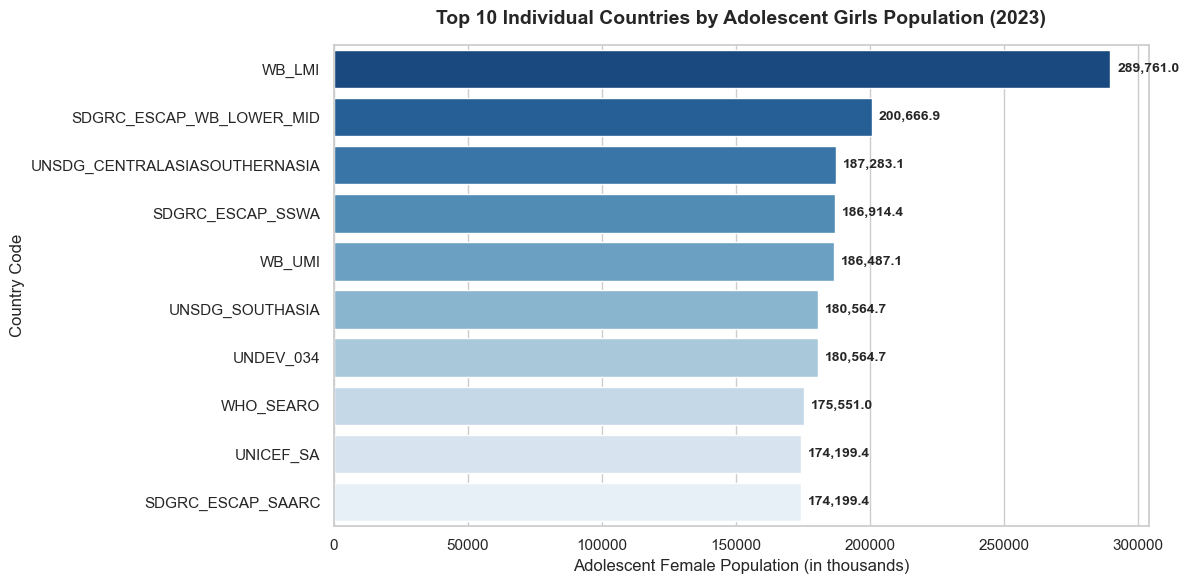

In [39]:
# 1. Filter out major global/regional codes to isolate individual countries
global_codes = ['WORLD', 'WHO_REG_GLOBAL', 'UNSDG_REGION_GLOBAL', 
                'UNICEF_REP_REG_GLOBAL', 'UNICEF_PROG_REG_GLOBAL', 
                'UNDEV_142', 'UNSDG_ASIA', 'SDGRC_ESCAP_ALL', 'UNFPA_EAP']
country_data=clean_data[(clean_data['REF_AREA'].isin(global_codes))&
            (clean_data['INDICATOR']=='DM_POP_ADLCNT')&
            (clean_data['SEX']=='F')&
            (clean_data['TIME_PERIOD']==2023)    
].copy()

# 2. Get the top 10 countries by female adolescent population

top_10_countries = clean_data.sort_values(by='OBS_VALUE', ascending=False).head(10)

# 3. Plot a professional Seaborn bar chart tailored for presentation
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=top_10_countries, 
    x='OBS_VALUE', 
    y='REF_AREA',  # You can replace this with 'COUNTRY_NAME' once mapped
    palette='Blues_r'
)

plt.title('Top 10 Individual Countries by Adolescent Girls Population (2023)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Adolescent Female Population (in thousands)', fontsize=12)
plt.ylabel('Country Code', fontsize=12)

# Add data labels on the bars
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f'{width:,.1f}',
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    xytext=(5, 0), textcoords='offset points',
                    fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

In [40]:
# filter out all regional and income groups and isolate only true individual countries.
country_only_data=clean_data[(clean_data['REF_AREA'].str.contains('_',na=False))&
                            (clean_data['INDICATOR'] == 'DM_POP_ADLCNT') & 
                            (clean_data['SEX'] == 'F') & 
                            (clean_data['TIME_PERIOD'] == 2023)
                            ].copy()
# 2. Map ISO country codes to readable names (if you haven't already defined country_region_mapping)
# For standard ISO codes, pycountry or a quick mapping works, but let's sort by OBS_VALUE first
top_10_countries=country_only_data.sort_values(by='OBS_VALUE', ascending=False).head(10)

print('Top 10 country codes and Values:')
print(top_10_countries[['REF_AREA','TIME_PERIOD','OBS_VALUE']])





Top 10 country codes and Values:
                              REF_AREA  TIME_PERIOD   OBS_VALUE
2101811                         WB_LMI         2023  289761.008
1312537       SDGRC_ESCAP_WB_LOWER_MID         2023  200666.858
499360   UNSDG_CENTRALASIASOUTHERNASIA         2023  187283.130
1277677               SDGRC_ESCAP_SSWA         2023  186914.405
2111935                         WB_UMI         2023  186487.100
1308117                      UNDEV_034         2023  180564.682
1315334                UNSDG_SOUTHASIA         2023  180564.682
1235040                      WHO_SEARO         2023  175550.960
1194547                      UNICEF_SA         2023  174199.362
1183103                    UNICEF_ROSA         2023  174199.362


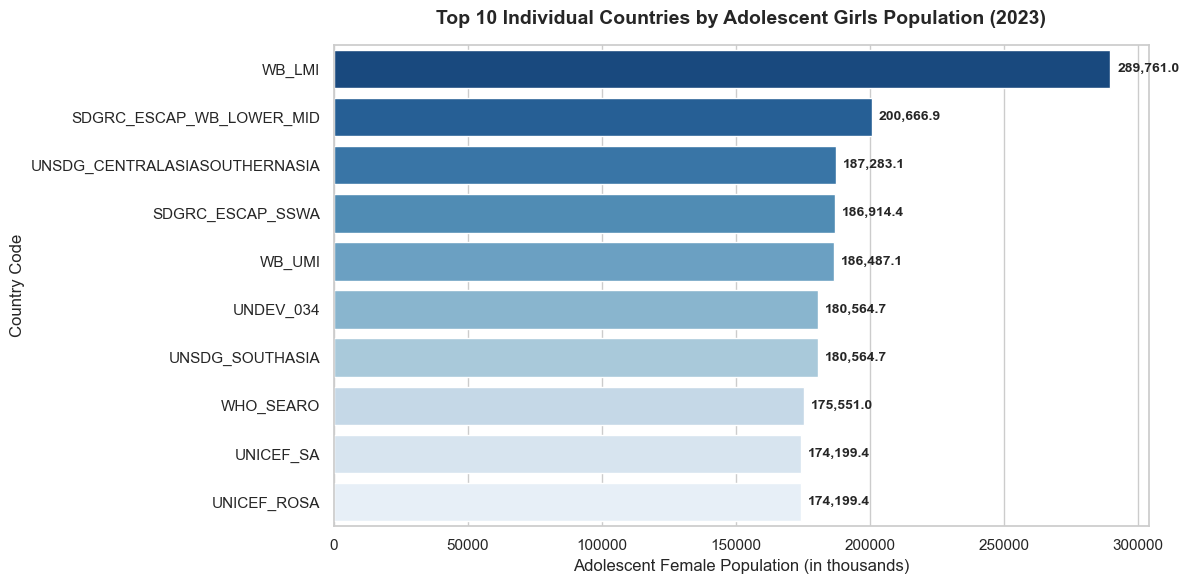

In [41]:
# seaborn plaos to further explain the above data
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=top_10_countries, 
    x='OBS_VALUE', 
    y='REF_AREA',  # You can replace this with 'COUNTRY_NAME' once mapped
    palette='Blues_r',
    hue='REF_AREA',
    legend=False
)

plt.title('Top 10 Individual Countries by Adolescent Girls Population (2023)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Adolescent Female Population (in thousands)', fontsize=12)
plt.ylabel('Country Code', fontsize=12)
#add label on the bar
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f'{width:,.1f}',
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    xytext=(5, 0), textcoords='offset points',
                    fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

In [42]:
"""
The Core Insight for Your UNICEF Story:
Your data is telling a powerful macro-level story: South Asia and Lower-Middle Income
countries are the global epicenter for adolescent girls. Millions of adolescents are 
concentrated in this region, meaning that global targets for education, health, and protection will be won or 
lost based on investments made here.
"""

'\nThe Core Insight for Your UNICEF Story:\nYour data is telling a powerful macro-level story: South Asia and Lower-Middle Income\ncountries are the global epicenter for adolescent girls. Millions of adolescents are \nconcentrated in this region, meaning that global targets for education, health, and protection will be won or \nlost based on investments made here.\n'

Top 10 Individual Countries (Codes & Values):
        REF_AREA  TIME_PERIOD   OBS_VALUE
2175810      IND         2023  121069.574
415161      OECD         2023   82444.905
581120       CHN         2023   78732.426
464267       PAK         2023   27030.079
259530       NGA         2023   26785.324
2197605      IDN         2023   23087.886
1834788      USA         2023   21376.965
2631313      BGD         2023   16464.023
1690801      ETH         2023   14552.119
116196       BRA         2023   14472.162


/var/folders/qj/qswms0r90q79_vs6_pmlnm340000gn/T/ipykernel_66006/2145634404.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


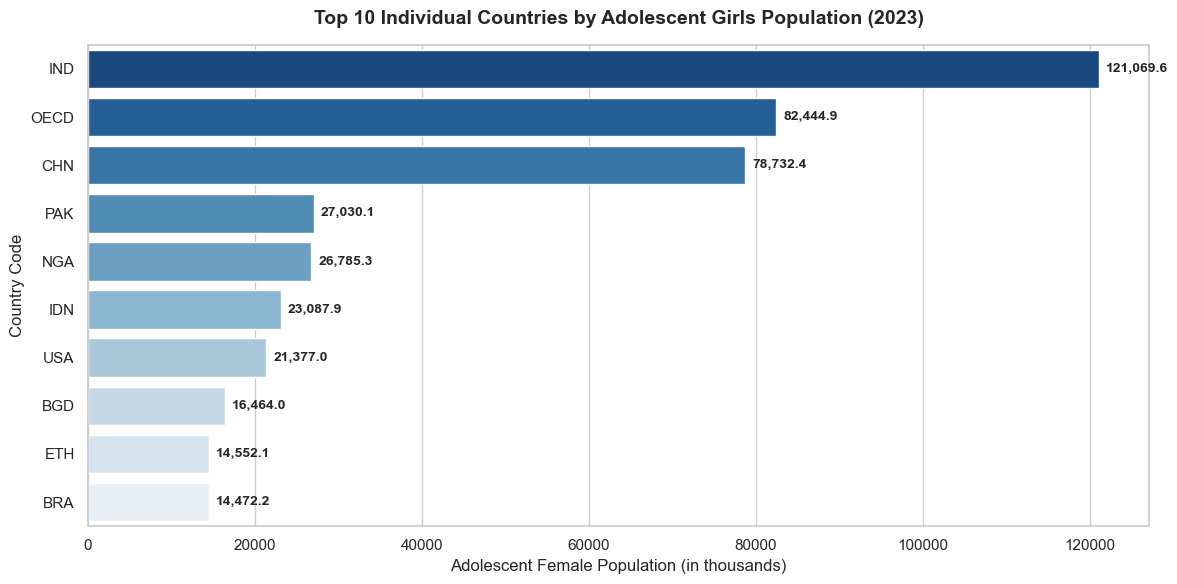

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filter out any REF_AREA containing an underscore (removes regional/income groups)
country_only_data = clean_data[
    (~clean_data['REF_AREA'].str.contains('_', na=False)) & 
    (clean_data['INDICATOR'] == 'DM_POP_ADLCNT') & 
    (clean_data['SEX'] == 'F') & 
    (clean_data['TIME_PERIOD'] == 2023)
].copy()

# 2. Sort by highest population values to get the top 10 individual countries
top_10_countries = country_only_data.sort_values(by='OBS_VALUE', ascending=False).head(10)

print("Top 10 Individual Countries (Codes & Values):")
print(top_10_countries[['REF_AREA', 'TIME_PERIOD', 'OBS_VALUE']])

# 3. Plot the individual country bar chart
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=top_10_countries, 
    x='OBS_VALUE', 
    y='REF_AREA', 
    palette='Blues_r'
)

plt.title('Top 10 Individual Countries by Adolescent Girls Population (2023)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Adolescent Female Population (in thousands)', fontsize=12)
plt.ylabel('Country Code', fontsize=12)

# Add data labels onto the bars
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f'{width:,.1f}',
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    xytext=(5, 0), textcoords='offset points',
                    fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

In [44]:
"""
The UNICEF Story Behind These Numbers:
The Asian Giants (India & China): While China's demographic curve is aging with a shrinking youth cohort, 
India is currently experiencing a massive youth and adolescent window—making education, digital skills, and
health investments critical for its economic future.
The Sub-Saharan Surge (Nigeria / NGA): Nigeria represents the frontline of the global youth boom. Unlike parts 
of Asia where youth populations are stabilizing, Sub-Saharan Africa's adolescent population is growing rapidly,
requiring urgent, scalable investments in health,
protection, and secondary education.
"""

"\nThe UNICEF Story Behind These Numbers:\nThe Asian Giants (India & China): While China's demographic curve is aging with a shrinking youth cohort, \nIndia is currently experiencing a massive youth and adolescent window—making education, digital skills, and\nhealth investments critical for its economic future.\nThe Sub-Saharan Surge (Nigeria / NGA): Nigeria represents the frontline of the global youth boom. Unlike parts \nof Asia where youth populations are stabilizing, Sub-Saharan Africa's adolescent population is growing rapidly,\nrequiring urgent, scalable investments in health,\nprotection, and secondary education.\n"

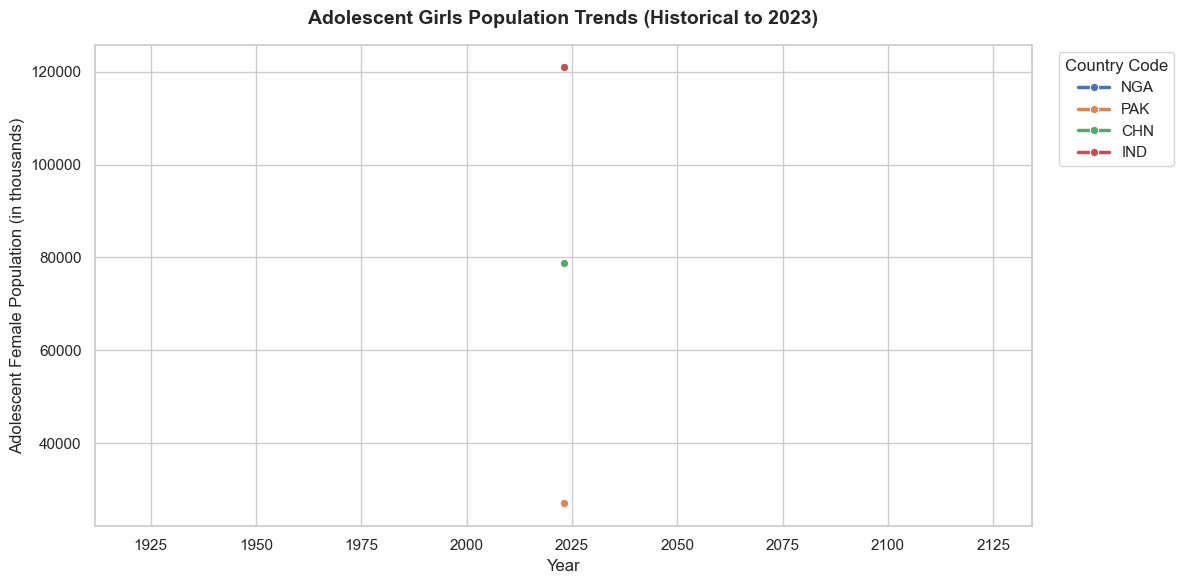

In [45]:
#let's look at how these populations have changed over the decades. 
#Are India and Nigeria still growing, and is China starting to flatten or decline?

# 1. Select key countries to compare (e.g., India, China, Nigeria, Pakistan)
# Note: Adjust codes if your dataset uses specific ISO codes like 'PAK' for Pakistan
target_countries = ['IND', 'CHN', 'NGA', 'PAK']

trend_data = clean_data[
    (clean_data['REF_AREA'].isin(target_countries)) & 
    (clean_data['INDICATOR'] == 'DM_POP_ADLCNT') & 
    (clean_data['SEX'] == 'F')
].copy()

# Ensure TIME_PERIOD is numeric for proper line plotting
trend_data['TIME_PERIOD'] = pd.to_numeric(trend_data['TIME_PERIOD'], errors='coerce')

# 2. Plot multi-line trends over time
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

sns.lineplot(
    data=trend_data, 
    x='TIME_PERIOD', 
    y='OBS_VALUE', 
    hue='REF_AREA', 
    linewidth=2.5,
    marker='o'
)

plt.title('Adolescent Girls Population Trends (Historical to 2023)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Adolescent Female Population (in thousands)', fontsize=12)
plt.legend(title='Country Code', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [52]:
#since we dont have a curve, it mean only a single year for the data is vaialble and so we use a bar chart to visualize this data
#example is INDIA
india_check =clean_data[
    (clean_data['REF_AREA'] == 'IND') & 
    (clean_data['INDICATOR'] == 'DM_POP_ADLCNT') & 
    (clean_data['SEX'] == 'F')
]

print(f"Total rows for India: {len(india_check)}")
print(india_check[['TIME_PERIOD', 'OBS_VALUE']].sort_values(by='TIME_PERIOD'))

Total rows for India: 1
         TIME_PERIOD   OBS_VALUE
2175810         2023  121069.574


Top 10 Countries by Adolescent Proportion (2023):
Empty DataFrame
Columns: [REF_AREA, TIME_PERIOD, OBS_VALUE]
Index: []


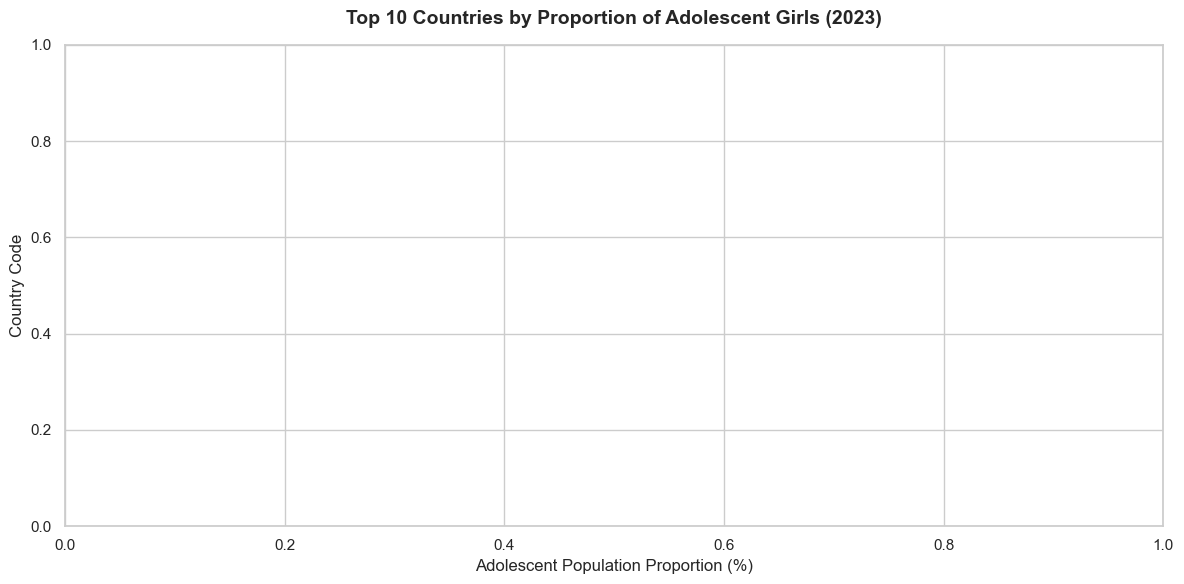

In [53]:
# 1. Filter for the proportion indicator ('DM_POP_ADLCNT_PROP'), individual countries, female, 2023
prop_data = clean_data[
    (~clean_data['REF_AREA'].str.contains('_', na=False)) & 
    (clean_data['INDICATOR'] == 'DM_POP_ADLCNT_PROP') & 
    (clean_data['SEX'] == 'F') & 
    (clean_data['TIME_PERIOD'] == 2023)
].copy()

# Ensure OBS_VALUE is numeric
prop_data['OBS_VALUE'] = pd.to_numeric(prop_data['OBS_VALUE'], errors='coerce')

# 2. Get top 10 countries by adolescent proportion
top_prop_countries = prop_data.sort_values(by='OBS_VALUE', ascending=False).head(10)

print("Top 10 Countries by Adolescent Proportion (2023):")
print(top_prop_countries[['REF_AREA', 'TIME_PERIOD', 'OBS_VALUE']])

# 3. Plot the bar chart with hue for visual clarity
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=top_prop_countries, 
    x='OBS_VALUE', 
    y='REF_AREA', 
    hue='REF_AREA',      # Uses hue to categorize colors cleanly
    palette='Purples_r',
    legend=False
)

plt.title('Top 10 Countries by Proportion of Adolescent Girls (2023)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Adolescent Population Proportion (%)', fontsize=12)
plt.ylabel('Country Code', fontsize=12)

# Add data labels on the bars
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f'{width:,.2f}%',
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    xytext=(5, 0), textcoords='offset points',
                    fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

In [57]:

prop_check=clean_data[clean_data['INDICATOR']=='DM_POP_ADLCNT_PROP']
print("Available Sex_Value:",prop_check['SEX'].unique())

Available Sex_Value: []


In [63]:

# 1. Ensure numeric types for both time and values
clean_data['TIME_PERIOD'] = pd.to_numeric(clean_data['TIME_PERIOD'], errors='coerce')
clean_data['OBS_VALUE'] = pd.to_numeric(clean_data['OBS_VALUE'], errors='coerce')

# 2. Filter for individual countries, proportion indicator, latest year (e.g., 2023), and total sex '_T' (or 'F' if available)
prop_data = clean_data[
    (~clean_data['REF_AREA'].str.contains('_', na=False)) & 
    (clean_data['INDICATOR'] == 'DM_POP_ADLCNT_PROP') & 
    (clean_data['SEX'] == '_T') & 
    (clean_data['TIME_PERIOD'] == 2023)
].copy()

# 3. Sort to get top 10 highest proportions
top_prop_countries = prop_data.sort_values(by='OBS_VALUE', ascending=False).head(10)

print(f"Found {len(top_prop_countries)} rows for the chart.")
print(top_prop_countries[['REF_AREA', 'TIME_PERIOD', 'OBS_VALUE']])

# 4. Plot the bar chart if data exists
if not top_prop_countries.empty:
    plt.figure(figsize=(12, 6))
    sns.set_theme(style="whitegrid")

    ax = sns.barplot(
        data=top_prop_countries, 
        x='OBS_VALUE', 
        y='REF_AREA', 
        hue='REF_AREA',
        palette='Purples_r',
        legend=False
    )

    plt.title('Top 10 Countries by Proportion of Adolescent Population (2023)', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Adolescent Population Proportion (%)', fontsize=12)
    plt.ylabel('Country Code', fontsize=12)

    # Add data labels on the bars
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(f'{width:,.2f}%',
                        (width, p.get_y() + p.get_height() / 2.),
                        ha='left', va='center',
                        xytext=(5, 0), textcoords='offset points',
                        fontsize=10, fontweight='semibold')

    plt.tight_layout()
    plt.show()
else:
    print("DataFrame is still empty. Check your diagnostic output above for available years or SEX codes!")

Found 0 rows for the chart.
Empty DataFrame
Columns: [REF_AREA, TIME_PERIOD, OBS_VALUE]
Index: []
DataFrame is still empty. Check your diagnostic output above for available years or SEX codes!


In [61]:
# 1. Convert TIME_PERIOD to numeric so comparisons work properly
clean_data['TIME_PERIOD'] = pd.to_numeric(clean_data['TIME_PERIOD'], errors='coerce')

# 2. Diagnostic: check available SEX values and years for the proportion indicator
prop_subset = clean_data[clean_data['INDICATOR'] == 'DM_POP_ADLCNT_PROP']
print("Available SEX categories for proportion:", prop_subset['SEX'].unique())
print("Available years for proportion:", prop_subset['TIME_PERIOD'].dropna().unique())

Available SEX categories for proportion: []
Available years for proportion: []


In [62]:
# 1. Strip any leading/trailing whitespace from string columns
for col in clean_data.select_dtypes(include=['object']).columns:
    clean_data[col] = clean_data[col].str.strip()

# 2. Re-check unique indicators to see if 'DM_POP_ADLCNT_PROP' appears now
print("Unique indicators found in dataset:")
print(clean_data['INDICATOR'].unique())

# 3. Test the proportion subset again
prop_subset = clean_data[clean_data['INDICATOR'] == 'DM_POP_ADLCNT_PROP']
print(f"\nTotal rows found for proportion indicator: {len(prop_subset)}")

if len(prop_subset) > 0:
    print("Available SEX categories for proportion:", prop_subset['SEX'].unique())
    print("Available years for proportion:", prop_subset['TIME_PERIOD'].unique())

Unique indicators found in dataset:
['DM_POP_ADLCNT']

Total rows found for proportion indicator: 0


Top 10 Individual Countries (2023):
        REF_AREA  TIME_PERIOD   OBS_VALUE
2175810      IND         2023  121069.574
415161      OECD         2023   82444.905
581120       CHN         2023   78732.426
464267       PAK         2023   27030.079
259530       NGA         2023   26785.324
2197605      IDN         2023   23087.886
1834788      USA         2023   21376.965
2631313      BGD         2023   16464.023
1690801      ETH         2023   14552.119
116196       BRA         2023   14472.162


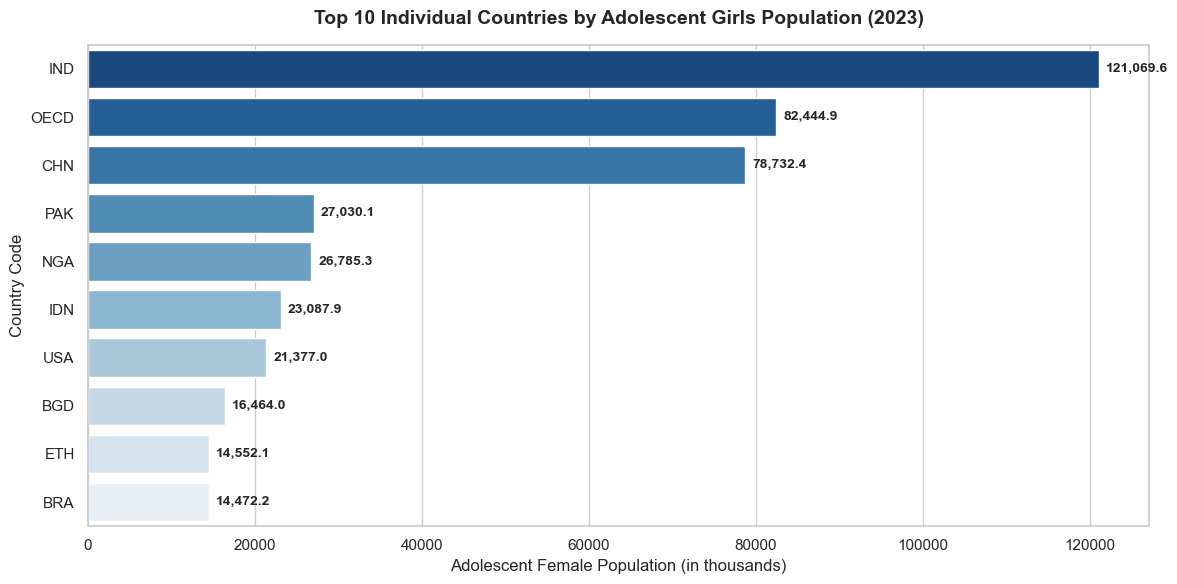

In [64]:

# 1. Ensure correct data types
clean_data['OBS_VALUE'] = pd.to_numeric(clean_data['OBS_VALUE'], errors='coerce')
clean_data['TIME_PERIOD'] = pd.to_numeric(clean_data['TIME_PERIOD'], errors='coerce')

# 2. Filter for individual countries, female adolescent count, and 2023 snapshot
country_data = clean_data[
    (~clean_data['REF_AREA'].str.contains('_', na=False)) & 
    (clean_data['INDICATOR'] == 'DM_POP_ADLCNT') & 
    (clean_data['SEX'] == 'F') & 
    (clean_data['TIME_PERIOD'] == 2023)
].copy()

# 3. Sort by highest population values to get the top 10 individual countries
top_10_countries = country_data.sort_values(by='OBS_VALUE', ascending=False).head(10)

print("Top 10 Individual Countries (2023):")
print(top_10_countries[['REF_AREA', 'TIME_PERIOD', 'OBS_VALUE']])

# 4. Plot a professional Seaborn bar chart
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=top_10_countries, 
    x='OBS_VALUE', 
    y='REF_AREA', 
    hue='REF_AREA',
    palette='Blues_r',
    legend=False
)

plt.title('Top 10 Individual Countries by Adolescent Girls Population (2023)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Adolescent Female Population (in thousands)', fontsize=12)
plt.ylabel('Country Code', fontsize=12)

# Add data labels onto the bars
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f'{width:,.1f}',
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    xytext=(5, 0), textcoords='offset points',
                    fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

In [ ]:
"""
India’s Unprecedented Scale & Demographic Dividend: As the global leader in adolescent female population (surpassing 121 million),
India represents a pivotal demographic window. Strategic investments in secondary education, digital literacy, and adolescent health 
are essential to transition this massive youth cohort into a powerful economic engine.
Nigeria’s Rapid Youth Surge & Social Infrastructure Demand: Anchoring Sub-Saharan Africa's demographic boom, Nigeria faces a steeply 
rising youth curve. Scaling up targeted investments in girls' education, health, and protection against systemic vulnerabilities is 
critical to harness this growth and prevent educational or economic bottlenecks.
Pivotal Frontlines for Global UNICEF Targets: Because global adolescent populations are heavily concentrated in these two distinct 
regions (South Asia and Sub-Saharan Africa), achieving international development goals and equity targets will ultimately be won or lost based on policy and funding execution in India and Nigeria.

"""